### Example: Equidistant geometry


In [1]:
import os 
#os.environ["JAX_PLATFORM_NAME"] = "cpu"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
import jax 
jax.config.update("jax_enable_x64", True)
import jax_sbgeom
import jax.numpy as jnp
%load_ext autoreload
%autoreload 2
import pyvista as pv
from jax_sbgeom.jax_utils import mesh_to_pyvista_mesh


In [2]:
vmec_file = "/home/rifat-hadi/backup/codes/vmecpp_examples/helias5_data/plasma/helias5_vmec.nc4"  
coil_file = "/home/rifat-hadi/backup/codes/vmecpp_examples/helias5_data/coils/HELIAS5_coils_all_corr.h5"

##### Setting up geometry

Selecting a particular coil and plasma set:

We use a FluxSurfaceConstantPhi, as this has the property that $\phi_{in} = \phi_{out}$ even beyond the LCFS (as required by FFTs). Furthermore, this creates a surface exactly the same as the original normal vector for constant $d$.

In [3]:
#from jax_sbgeom.flux_surfaces import FluxSurfaceNormalExtendedConstantPhi, ToroidalExtentStatic
#full_extent1 = ToroidalExtentStatic.full()
from jax_sbgeom.flux_surfaces import FluxSurfaceNormalExtendedConstantPhi, ToroidalExtent
# One complete 72-degree field period of the five-period stellarator.
full_extent1 = ToroidalExtent(start=0.0, end=jnp.deg2rad(360))
from jax_sbgeom.coils         import CoilSet, DiscreteCoil, convert_to_fourier_coilset, RotationMinimizedFrame, FiniteSizeCoilSet
flux_surface = FluxSurfaceNormalExtendedConstantPhi.from_hdf5(vmec_file)
def _get_discrete_coils(coil_file):
    import h5py
    with h5py.File(coil_file, 'r') as f:
        coil_data = jnp.array(f['Dataset1'])
    return CoilSet.from_list([DiscreteCoil.from_positions(coil_data[i]) for i in range(coil_data.shape[0])])

coilset      = _get_discrete_coils(coil_file)
fourier_coilset = convert_to_fourier_coilset(coilset)
fs_coilset      = FiniteSizeCoilSet.from_coilset(fourier_coilset, RotationMinimizedFrame, 100)

We load a HCPB blanket from a JSON file that describes layering and element compositions

In [4]:
import json
with open("hcpb_blanket.json") as f:
    blanket_data = json.load(f)

In [5]:
# Minimum_div_13%

import jax_sbgeom.interfaces.blanket_creation as bc

fw_distance = 0.10

n_theta_blanket = 50
n_phi_blanket   = 100 * 5

resolutions_blanket = [10, 1, 1, 6, 4, 3, 4, 3]

layer_names = [
    "TungstenArmor",
    "FirstWall",
    "BreedingZone",
    "BackSupportingStructure",
    "InnerVacuumVessel",
    "VVShield",
    "OuterVacuumVessel",
]

thicknesses = [
    0.007,  # Tungsten Armor
    0.02,  # First Wall
    0.50,   # Breeding Zone
    0.12,   # Back Support Structure
    0.06,   # Inner Vacuum Vessel
    0.20,   # VV Shield
    0.06,   # Outer Vacuum Vessel
]

layers_jax = jnp.concatenate([jnp.array([0.0]), jnp.cumsum(jnp.array(thicknesses))]) + fw_distance

# Over one field period each divertor follows the sharp plasma edge from
# one strike-point angle to the other.  poloidal_end makes the footprint
# diagonal in (theta, phi), rather than a constant-theta rectangle.
divertor_thicknesses = (
    0.008,     # Divertor Armor
    0.023,     # Heat Sink
    0.49996,   # Divertor Shield + cooling channels
    0.12,      # Back Support Structure
    0.06,      # Inner Vacuum Vessel
    0.20,      # VV Shield
    0.06       # Outer Vacuum Vessel
)
divertor_layer_names = (
    "DivertorArmor", 
    "DivertorHeatSink", 
    "DivertorShield", 
    "BackSupportingStructure",
    "InnerVacuumVessel",
    "VVShield",
    "DivertorOuterVacuumVessel"
)
divertor_toroidal_width = jnp.deg2rad(72)
divertors = (
    bc.Divertor(jnp.deg2rad(85.0), jnp.deg2rad(24), 0.0, divertor_toroidal_width,
                divertor_layer_names, divertor_thicknesses, replicate=5,
                poloidal_end=jnp.deg2rad(250.0)),
    bc.Divertor(jnp.deg2rad(250.0), jnp.deg2rad(24), 0.0, divertor_toroidal_width,
                divertor_layer_names, divertor_thicknesses, replicate=5,
                poloidal_end=jnp.deg2rad(85.0)),
)

discrete_blanket = bc.LayeredDiscreteBlanketPlasmaTransformed(
    n_theta=n_theta_blanket, n_phi=n_phi_blanket,
    resolution_layers=tuple(resolutions_blanket), toroidal_extent=full_extent1,
    s_power_sampling=2.0, divertors=divertors,
)
discrete_coilset = bc.DiscreteFiniteSizeCoilSet(
    n_points_per_coil=500, toroidal_extent=full_extent1,
    width_R=0.3, width_phi=0.3
)

coil_vertices, coil_connectivity = jax_sbgeom.coils.mesh_coilset_surface(
    fs_coilset, discrete_coilset.n_points_per_coil,
    discrete_coilset.width_R, discrete_coilset.width_phi
)

# No element masks or material overrides are required: Divertor is meshed
# as an independent, normal-offset multilayer component by the DAGMC path.

In [6]:
#inactive
def create_openmc_material_from_elements(material_dict, name):
    elements_i = material_dict["Elements"]
    mat_i = openmc.Material(name = name)        
    total_atom_number = sum(elements_i.values())
    for atom in elements_i.keys():
        nuclide_name = atom.title()
        if atom.title() == "D":
            nuclide_name = "H2"
        mat_i.add_nuclide(nuclide_name , elements_i[atom] / total_atom_number, 'ao')
    mat_i.set_density("atom/cm3", float(total_atom_number) * 1e-6) # m3 -> cm3
    return mat_i

In [7]:
#inactive 
total_material_dict = {}
import openmc
for i in blanket_data.keys():    
    total_material_dict[i] = create_openmc_material_from_elements(blanket_data[i], i)
# Add coil material (same as BackSupportingStructure)    
total_material_dict['Coil'] = create_openmc_material_from_elements(blanket_data['BackSupportingStructure'], 'Coil')

We then generate an equal-arclength representation of the all flux surface layers:

In [8]:
from jax_sbgeom.flux_surfaces.convert_to_vmec import (
    create_extended_flux_surface_d_interp_equal_arclength
)

fs_total = create_extended_flux_surface_d_interp_equal_arclength(
    flux_surface,
    layers_jax,
    flux_surface.settings.mpol * 6,
    flux_surface.settings.ntor * 6,
    100,
)

We can mesh the geometry:

In [9]:
surfaces = jax_sbgeom.flux_surfaces.mesh_watertight_layers(
    fs_total,
    2.0 + jnp.arange(len(layers_jax)),
    discrete_blanket.toroidal_extent,
    discrete_blanket.n_theta,
    discrete_blanket.n_phi,
)

In [10]:
n_plasma_source = 10
tetrahedral_plasma_mesh = jax_sbgeom.flux_surfaces.mesh_tetrahedra(flux_surface, jnp.linspace(0,1,10) **2, discrete_blanket.toroidal_extent, discrete_blanket.n_theta, discrete_blanket.n_phi)
n0 = 2.123e20
Ti0=  15.2
nalpha = 0.35
Tialpha = 1.2
s = jnp.linspace(0, 1, 100)
fs_rates = jax_sbgeom.interfaces.plasma.flux_surface_reaction_rates_simple(s, n0, nalpha, Ti0, Tialpha)

In [11]:
s_axis = jnp.zeros(discrete_blanket.n_phi)
s_layers = jnp.broadcast_to((jnp.linspace(0,1, n_plasma_source)[1:][:, None])**2, (n_plasma_source - 1, discrete_blanket.n_phi *  discrete_blanket.n_theta)).ravel()
s_total = jnp.concatenate([s_axis, s_layers])
neutron_rates_mesh = jax_sbgeom.interfaces.plasma.flux_surface_reaction_rates_simple(s_total, n0, nalpha, Ti0, Tialpha)

In [12]:
# Plot the actual closed component meshes used by DAGMC.

def component_to_pyvista(points, triangles):
    faces = np.column_stack((np.full(len(triangles), 3), np.asarray(triangles))).ravel()
    return pv.PolyData(np.asarray(points), faces)

component_meshes = discrete_blanket.volume_surface_meshes(fs_total)
'''
component_colors = {
    "TungstenArmor": "gold",
    "FirstWall": "yellow",
    "BreedingZone": "mediumseagreen",
    "BackSupportingStructure": "orange",
    "InnerVacuumVessel": "purple",
    "VVShield": "silver",
    "OuterVacuumVessel": "purple",
    "DivertorArmor": "deeppink",
    "DivertorHeatSink": "red",
    "DivertorShield": "blue", 
    "DivertorOuterVacuumVessel": "lightblue"
}
plotter = pv.Plotter()
blanket_layer_index = 0
seen_materials = []

for points, triangles, material in component_meshes:
    if material is None:
        material = layer_names[blanket_layer_index]
        blanket_layer_index += 1

    seen_materials.append(material)
    plotter.add_mesh(
        component_to_pyvista(points, triangles),
        color=component_colors.get(material, "lightsteelblue"),
        show_edges=False,
        opacity=1.0,
        label=material,
    )
'''
'''
plotter.add_mesh(
    mesh_to_pyvista_mesh(coil_vertices, coil_connectivity),
    color="gray",
    show_edges=False,
    label="Coils",
)'''
'''
plotter.add_legend()
plotter.view_isometric()
plotter.show()
print("Mesh component order:", seen_materials)'''

'\nplotter.add_legend()\nplotter.view_isometric()\nplotter.show()\nprint("Mesh component order:", seen_materials)'

In [13]:
import numpy as np
requested = np.asarray(divertor_thicknesses, dtype=float)
names = tuple(divertor_layer_names)
assert requested.ndim == 1 and len(requested) == len(names)
assert np.all(requested > 0.0)
total = requested.sum()
cumulative = np.r_[0.0, np.cumsum(requested)]
fractions = np.diff(cumulative) / total
print(f"Requested divertor stack thickness: {total:.9f} m")
print(f"{'Layer':>28s} {'input (m)':>12s} {'fraction':>14s} {'cumulative end':>16s}")
for name, thickness, fraction, end in zip(names, requested, fractions, cumulative[1:]):
    print(f"{name:>28s} {thickness:12.6f} {fraction:14.9f} {end:16.6f}")

# Verify every Divertor object, not just the local input tuple.
for divertor in divertors:
    actual = np.asarray(divertor.thicknesses, dtype=float)
    assert tuple(divertor.layer_names) == names
    assert np.allclose(actual, requested, rtol=0.0, atol=1e-12)
print(f"\nVerified {len(divertors)} divertor definitions: all eight thicknesses match.")

# Confirm that every requested divertor material produced a mesh.
for name in names:
    matching = [points for points, _, material in component_meshes if material == name]
    assert matching, f"No generated mesh found for {name}"
    print(f"{name:>28s}: components={len(matching)}, points={sum(len(p) for p in matching):d}")

print(f"\nExpected visual ratio DivertorShield/DivertorBreedingZone: {requested[2] / requested[3]:.6f}")
print(f"The breeding zone is {requested[3] / requested[2]:.3f}x thicker than the shield.")

Requested divertor stack thickness: 0.970960000 m
                       Layer    input (m)       fraction   cumulative end
               DivertorArmor     0.008000    0.008239268         0.008000
            DivertorHeatSink     0.023000    0.023687897         0.031000
              DivertorShield     0.499960    0.514913076         0.530960
     BackSupportingStructure     0.120000    0.123589025         0.650960
           InnerVacuumVessel     0.060000    0.061794513         0.710960
                    VVShield     0.200000    0.205981709         0.910960
   DivertorOuterVacuumVessel     0.060000    0.061794513         0.970960

Verified 2 divertor definitions: all eight thicknesses match.
               DivertorArmor: components=10, points=810000
            DivertorHeatSink: components=10, points=810000
              DivertorShield: components=10, points=540000
     BackSupportingStructure: components=10, points=810000
           InnerVacuumVessel: components=10, points=810000


In [14]:
'''
Tungsten: (wt.%): 99.9711W, 0.01Si, 0.005Ni, 0.005Fe, 0.002N, 0.002O, 0.0049C
    Source: "Neutronics analysis and activation calculation for Tungsten used in the DEMO divertor targets: A comparative study between the effects of WCLL and HCPB blanket, different W"
'''
tungsten = openmc.Material(name="Tungsten", material_id=1)
tungsten.add_element("W", 99.9711, 'wo')
tungsten.add_element("Si", 0.01, 'wo')
tungsten.add_element("Ni", 0.005, 'wo')
tungsten.add_element("Fe", 0.005, 'wo')
tungsten.add_element("N", 0.002, 'wo')
tungsten.add_element("O", 0.002, 'wo')
tungsten.add_element("C", 0.0049, 'wo')
tungsten.set_density('g/cm3', 19.105)
tungsten.depletable = True

'''
Copper:
    Source: "Neutronics analysis and activation calculation for Tungsten used in the DEMO divertor targets: A comparative study between the effects of WCLL and HCPB blanket, different W"
    (wt.%): 99.999433Cu, 0.0006S, 0.0003O, 0.0002P, 0.0001Zn, 0.00001Te, 0.0001Sn, 0.0001Se, 0.0001Sb, 0.0001Pb, 0.001Ni, 0.00005Mn, 0.001Fe, 0.0001Cd, 0.00001Bi, 0.0005As, 0.0014Ag 
'''
copper = openmc.Material(name="Copper", material_id=2)
copper.add_element("Cu", 99.999433, 'wo')
copper.add_element("S", 0.0006, 'wo')
copper.add_element("O", 0.0003, 'wo')
copper.add_element("P", 0.0002, 'wo')
copper.add_element("Zn", 0.0001, 'wo')
copper.add_element("Te", 0.00001, 'wo')
copper.add_element("Sn", 0.0001, 'wo')
copper.add_element("Se", 0.0001, 'wo')
copper.add_element("Sb", 0.0001, 'wo')
copper.add_element("Pb", 0.0001, 'wo')
copper.add_element("Ni", 0.001, 'wo')
copper.add_element("Mn", 0.00005, 'wo')
copper.add_element("Fe", 0.001, 'wo')
copper.add_element("Cd", 0.0001, 'wo')
copper.add_element("Bi", 0.00001, 'wo')
copper.add_element("As", 0.0005, 'wo')
copper.add_element("Ag", 0.0014, 'wo')
copper.set_density('g/cm3', 8.96)
copper.depletable = True

water=openmc.Material(material_id=3, name = "Water")
water.add_element("H", 2.0,'ao')
water.add_element("O", 1.0,'ao')
water.set_density("g/cm3", 1.0)
#water.add_s_alpha_beta('c_H_in_H2O')

Be=openmc.Material(material_id=4, name = "Beryllium")
Be.add_element("Be", 1.0,'ao')
Be.set_density("g/cm3", 1.848)
Be.depletable = True

he=openmc.Material(material_id=5, name="Helium")
he.add_element("He", 1.0,'ao')
he.set_density("g/cm3", 0.0001663)

'''
CuCrZr: (wt.%): 1.02Cr, 0.0779Zr, 0.0320Fe, 0.0428Si, balance Cu
    Source: "Determination of Production Parameters of CuCrZr Alloy by Selective Laser Melting Process"
'''
CuCrZr = openmc.Material(name="CuCrZr", material_id=6)
CuCrZr.add_element("Cr", 1.02, 'wo')
CuCrZr.add_element("Zr", 0.0779, 'wo')
CuCrZr.add_element("Fe", 0.0320, 'wo')
CuCrZr.add_element("Si", 0.0428, 'wo')
CuCrZr.add_element("Cu", 98.8273, 'wo')
CuCrZr.set_density('g/cm3', 8.9)
CuCrZr.depletable = True

'''
PbLi:
    It is a Pb rich composition
    Source: "Neutronics analysis and activation calculation for Tungsten used in the DEMO divertor targets: A comparative study between the effects of WCLL and HCPB blanket, different W"
    84.2% Pb and 15.8% Li
    Study: Lithium enrichment
'''
dcll=openmc.Material(material_id=7, name="DCLL")
dcll.add_element("Li", 0.158,'ao',
                 enrichment=90, 
                 enrichment_target='Li6', 
                 enrichment_type='ao'
                 )
dcll.add_element("Pb", 0.842,'ao')
dcll.set_density("g/cm3", 9.8)
dcll.depletable = True


'''
Eurofer97:
    Suggested By: "Advancements in Designing the DEMO Driver Blanket System at the EU DEMO Pre-Conceptual Design Phase: Overview, Challenges and Opportunities."
    Source: "Metallurgical characterization of the reduced activation ferritic/martensitic steel Eurofer'97 on as-received condition."ArithmeticError
    (wt.%): 0.11C, 8.7Cr, 1W, 0.10Ta, 0.19V, 0.44Mn, 0.004S, balance Fe
'''
eurofer97 = openmc.Material(name="Eurofer97", material_id=8)
eurofer97.add_element("C", 0.11, 'wo')
eurofer97.add_element("Cr", 8.7, 'wo')
eurofer97.add_element("W", 1.0, 'wo')
eurofer97.add_nuclide("Ta180", 0.10, 'wo')
eurofer97.add_nuclide("Ta181", 0.10, 'wo')
eurofer97.add_nuclide("Ta182", 0.10, 'wo')
eurofer97.add_element("V", 0.19, 'wo')
eurofer97.add_element("Mn", 0.44, 'wo')
eurofer97.add_element("S", 0.004, 'wo')
eurofer97.add_element("Fe", 89.456, 'wo')
eurofer97.set_density('g/cm3', 7.87)
eurofer97.depletable = True


'''
AISI 316SS:
    Suggested By: Advancements in Designing the DEMO Driver Blanket System at the EU DEMO Pre-Conceptual Design Phase: Overview, Challenges and Opportunities."
    Source: "Effect of Nickel Content and Cooling Rate on the Microstructure of as Cast 316 Stainless Steels."
    (wt.%): ≤0.08C, ≤1Si, ≤2Mn, ≤0.045P, ≤0.03S, 16–18Cr, 10–14Ni, 2–3Mo, ≤0.1N, Bal.Fe
    will be used in Vacuum vessel. 
    Study: 316L, 316M, 316H 
    Details: can be found in the same paper
'''
ss316ln = openmc.Material(name="AISI-316SS", material_id=9)
ss316ln.add_element("C", 0.08, 'wo')
ss316ln.add_element("Si", 1.0, 'wo')
ss316ln.add_element("Mn", 2.0, 'wo')
ss316ln.add_element("P", 0.045, 'wo')
ss316ln.add_element("S", 0.03, 'wo')
ss316ln.add_element("Cr", 17.0, 'wo')
ss316ln.add_element("Ni", 12.0, 'wo')
ss316ln.add_element("Mo", 2.5, 'wo')
ss316ln.add_element("N", 0.1, 'wo')
ss316ln.add_element("Fe", 65.245, 'wo')
ss316ln.set_density('g/cm3', 7.98)
ss316ln.depletable = True


Nb3Sn = openmc.Material(name="Nb3Sn", material_id=600)
Nb3Sn.add_element("Nb", 3, 'ao')
Nb3Sn.add_element("Sn", 1, 'ao')
Nb3Sn.set_density('g/cm3', 8.76)
Nb3Sn.depletable = True

bronze = openmc.Material(name="Bronze", material_id=601)
bronze.add_element("Cu", 88, 'wo')
bronze.add_element("Sn", 12, 'wo')
bronze.set_density('g/cm3', 8.8)
bronze.depletable = True

# r-epoxy (radiation-hardened epoxy resin, ~ITER magnet insulation)
# Using weight fractions from ITER magnet insulation references
# Density ~1.2–1.3 g/cm³ (use 1.25 as typical)
r_epoxy = openmc.Material(name='r_epoxy')
r_epoxy.add_element('H',  0.0601, percent_type='wo')
r_epoxy.add_element('C',  0.7061, percent_type='wo')
r_epoxy.add_element('N',  0.0200, percent_type='wo')
r_epoxy.add_element('O',  0.1951, percent_type='wo')
r_epoxy.add_element('Cl', 0.0187, percent_type='wo')
r_epoxy.set_density('g/cm3', 1.25)
r_epoxy.depletable = True

helium_liq = openmc.Material(name='helium_liquid')
helium_liq.add_nuclide('He4', 1.0, percent_type='ao')
helium_liq.set_density('g/cm3', 0.147)
helium_liq.depletable = True


def make_li4sio4(li6_enrichment=0.60):
    mat = openmc.Material(name="Li4SiO4",material_id=50)
    li_ao = 4
    mat.add_nuclide("Li6", li_ao * li6_enrichment,       'ao')
    mat.add_nuclide("Li7", li_ao * (1 - li6_enrichment),  'ao')
    mat.add_element("Si", 1, 'ao')
    mat.add_element("O",  4, 'ao')
    mat.set_density('g/cm3', 2.39)
    return mat

li4sio4  = make_li4sio4(li6_enrichment=0.60)
li4sio4.depletable = True

/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=1.
  warn(msg, IDWarning)
/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=2.
  warn(msg, IDWarning)
/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=3.
  warn(msg, IDWarning)
/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=4.
  warn(msg, IDWarning)
/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=5.
  warn(msg, IDWarning)
/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: A

### Coupling to OpenMC

In [15]:
'''HCPB layer temperatures:
Tungsten armor: 550C
First wall: 445.8C
Breeding zone: 588C
Back supporting structure: 328.5C
VV inner: 230C
VV shield: 205C
VV outer: 180C

source: https://scipub.euro-fusion.org/wp-content/uploads/eurofusion/WPS2CPR18_20145_submitted-4.pdf 
https://onlinelibrary.wiley.com/doi/epdf/10.1002/er.7343
'''


#this material is for blanket
TungstenArmor= openmc.Material.mix_materials([tungsten], [1.0],'vo', material_id=101)
TungstenArmor.name="TungstenArmor"
TungstenArmor.temperature = 823.15 # 550C
TungstenArmor.depletable = True

FirstWall= openmc.Material.mix_materials([eurofer97,he], [0.68,0.32],'vo', material_id=102)
FirstWall.name="FirstWall"
FirstWall.temperature = 719.85 # 445.8C
FirstWall.depletable = True

BreedingZone= openmc.Material.mix_materials([dcll,eurofer97,he], [0.938,0.061,0.001],'vo', material_id=103)
BreedingZone.name="BreedingZone"
BreedingZone.temperature = 861.15 # 588C
BreedingZone.depletable = True

BackSupportingStructure= openmc.Material.mix_materials([eurofer97,he], [0.79,0.21],'vo', material_id=104)
BackSupportingStructure.name="BackSupportingStructure"
BackSupportingStructure.temperature = 601.65 # 328.5C
BackSupportingStructure.depletable = True

VVShield=openmc.Material.mix_materials([ss316ln,water], [0.60,0.40],'vo', material_id=106)
VVShield.add_s_alpha_beta('c_H_in_H2O')
VVShield.name="VVShield"
VVShield.temperature = 478.15 # 205C
VVShield.depletable = True

InnerVacuumVessel = openmc.Material.mix_materials([ss316ln], [1.0], 'vo', material_id=108)
InnerVacuumVessel.name = 'InnerVacuumVessel'
InnerVacuumVessel.temperature = 503.15 # 230C
InnerVacuumVessel.depletable = True

OuterVacuumVessel = openmc.Material.mix_materials([ss316ln], [1.0], 'vo', material_id=109)
OuterVacuumVessel.name = 'OuterVacuumVessel'
OuterVacuumVessel.temperature = 453.15 # 180C
OuterVacuumVessel.depletable = True

Coil=openmc.Material.mix_materials([r_epoxy, Nb3Sn, bronze, copper, helium_liq, ss316ln], [0.18, 0.02895, 0.0735, 0.1169, 0.1682, 0.43245],'vo', material_id=110)
Coil.name="Coil"
Coil.add_s_alpha_beta('c_H_in_CH2')
Coil.depletable = True

DivertorArmor = openmc.Material.mix_materials([tungsten], [1.0], 'vo', material_id=111)
DivertorArmor.name = 'DivertorArmor'
DivertorArmor.depletable = True

DivertorHeatSink = openmc.Material.mix_materials([copper, CuCrZr, water], [0.13, 0.62, 0.25], 'vo', material_id=112)
DivertorHeatSink.name = 'DivertorHeatSink'
DivertorHeatSink.depletable = True

DivertorBreedingZone = openmc.Material.mix_materials([dcll, eurofer97, water], [0.938, 0.061, 0.001], 'vo', material_id=113)
DivertorBreedingZone.name = 'DivertorBreedingZone'
DivertorBreedingZone.depletable = True

DivertorShield = openmc.Material.mix_materials([eurofer97, water], [0.57, 0.43], 'vo', material_id=114)
DivertorShield.name = 'DivertorShield'
DivertorShield.depletable = True

DivertorOuterVacuumVessel = openmc.Material.mix_materials([ss316ln], [1.0], 'vo', material_id=115)
DivertorOuterVacuumVessel.name = 'DivertorOuterVacuumVessel'
DivertorOuterVacuumVessel.depletable = True

materials = openmc.Materials([
    TungstenArmor, FirstWall, BreedingZone, BackSupportingStructure,
    VVShield, InnerVacuumVessel, OuterVacuumVessel, Coil,
    DivertorArmor, DivertorHeatSink, DivertorBreedingZone, DivertorShield, DivertorOuterVacuumVessel
])
materials.export_to_xml()

In [16]:
def create_openmc_material_from_elements(material_dict, name):
    elements_i = material_dict["Elements"]
    mat_i = openmc.Material(name = name)        
    total_atom_number = sum(elements_i.values())
    for atom in elements_i.keys():
        nuclide_name = atom.title()
        if atom.title() == "D":
            nuclide_name = "H2"
        mat_i.add_nuclide(nuclide_name , elements_i[atom] / total_atom_number, 'ao')
    mat_i.set_density("atom/cm3", float(total_atom_number) * 1e-6) # m3 -> cm3
    return mat_i


In [17]:
# Divertor material names come from Divertor.layer_names; blanket names
# remain the positional material_names argument.

names = layer_names
dagmc_material_names = set(layer_names) | set(divertor_layer_names)
define_material_names = {material.name for material in materials}
missing_materials = dagmc_material_names - define_material_names
assert not missing_materials, f"Missing OpenMC materials for DAGMC groups: {sorted(missing_materials)}"
dagmc_surface_model = jax_sbgeom.interfaces.dagmc_interface.create_dagmc_surface_mesh(
    discrete_blanket, fs_total, names, fs_coilset, discrete_coilset, 'Coil'
)
dagmc_surface_model_filename = "dagmc_helias5_36_divertor.h5m"
dagmc_surface_model.write_file(dagmc_surface_model_filename)

dagmc_surface_model_filename = "dagmc_helias5_36_divertor.h5m"
dagmc_univ = openmc.DAGMCUniverse(filename=dagmc_surface_model_filename).bounded_universe()
geometry   = openmc.Geometry(root = dagmc_univ)
geometry.export_to_xml()

In [18]:
import dagmc_h5m_file_inspector as di
di.get_volumes_by_cell_id_and_material_name("dagmc_helias5_36_divertor.h5m", backend="pymoab")

{(1, 'TungstenArmor'): np.float64(12473583.260331137),
 (2, 'FirstWall'): np.float64(35852595.34816596),
 (3, 'BreedingZone'): np.float64(1002237696.0384196),
 (4, 'BackSupportingStructure'): np.float64(269604581.0557141),
 (5, 'InnerVacuumVessel'): np.float64(139136044.6838743),
 (6, 'VVShield'): np.float64(484668676.96941125),
 (7, 'OuterVacuumVessel'): np.float64(151605065.4209147),
 (8, 'DivertorArmor'): np.float64(192520.5020475644),
 (9, 'DivertorHeatSink'): np.float64(557000.7730203603),
 (10, 'DivertorShield'): np.float64(13596730.250772532),
 (11, 'BackSupportingStructure'): np.float64(3684035.2801934397),
 (12, 'InnerVacuumVessel'): np.float64(1901466.1793218052),
 (13, 'VVShield'): np.float64(6622536.08427346),
 (14, 'DivertorOuterVacuumVessel'): np.float64(2072412.2913685914),
 (15, 'DivertorArmor'): np.float64(192520.50204753302),
 (16, 'DivertorHeatSink'): np.float64(557000.7730208713),
 (17, 'DivertorShield'): np.float64(13596730.250772443),
 (18, 'BackSupportingStructur

In [ ]:
blanket_armor_surface_area = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=1, backend="pymoab")[0]

divertor_armor_surface_area1 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=8, backend="pymoab")[0]
divertor_armor_surface_area2 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=15, backend="pymoab")[0]
divertor_armor_surface_area3 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=22, backend="pymoab")[0]
divertor_armor_surface_area4 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=29, backend="pymoab")[0]
divertor_armor_surface_area5 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=36, backend="pymoab")[0]
divertor_armor_surface_area6 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=43, backend="pymoab")[0]
divertor_armor_surface_area7 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=50, backend="pymoab")[0]
divertor_armor_surface_area8 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=57, backend="pymoab")[0]
divertor_armor_surface_area9 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=64, backend="pymoab")[0]
divertor_armor_surface_area10 = di.get_surface_area_by_cell_id("dagmc_helias5_36_divertor.h5m", cell_id=71, backend="pymoab")[0]

divertor_armor_surface_area = (
    divertor_armor_surface_area1 + divertor_armor_surface_area2 + divertor_armor_surface_area3 + divertor_armor_surface_area4 + divertor_armor_surface_area5 +
    divertor_armor_surface_area6 + divertor_armor_surface_area7 + divertor_armor_surface_area8 + divertor_armor_surface_area9 + divertor_armor_surface_area10
)

surface_area_fraction_divertor_armor = (divertor_armor_surface_area / (blanket_armor_surface_area + divertor_armor_surface_area)) * 100.0

print(f"Blanket armor surface area: {blanket_armor_surface_area:.6f}")
print(f"Divertor armor surface area: {divertor_armor_surface_area:.6f}")
print(f"Fraction of total armor surface area in divertor: {surface_area_fraction_divertor_armor:.6f}%")

We can plot the OpenMC geometry:

We define a plasma source derived from some simple parametric values:

In [ ]:
tetrahedral_plasma_mesh1 = jax_sbgeom.flux_surfaces.mesh_tetrahedra(flux_surface, jnp.linspace(0,1,10) **2, discrete_blanket.toroidal_extent, discrete_blanket.n_theta, discrete_blanket.n_phi)

Text(0, 0.5, 'Neutron source density [m^{-3} s^{-1}]')

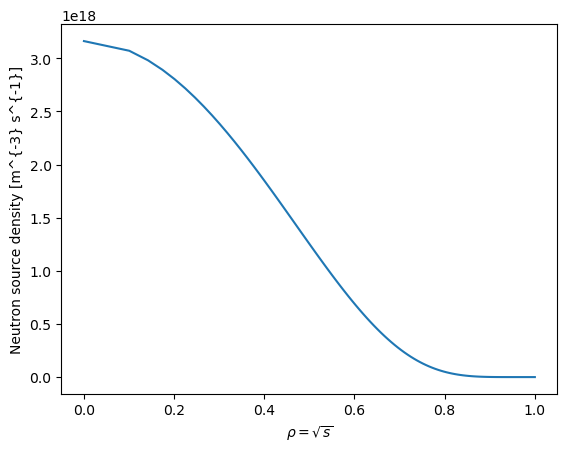

In [ ]:
import matplotlib.pyplot as plt
plt.plot(jnp.sqrt(s), fs_rates)
plt.xlabel(r"$\rho = \sqrt{s}$")
plt.ylabel("Neutron source density [m^{-3} s^{-1}]")

Then, we create a tetrahedral mesh for the geometry:

We need to map that to the source values by using that the first axis of the mesh points is the layering:

Then, we average it for each tetrahedron:

In [ ]:
tet_volumes = jax_sbgeom.jax_utils.mesh.volumes_tetrahedra(*tetrahedral_plasma_mesh1)
rates_element = jnp.mean(neutron_rates_mesh[tetrahedral_plasma_mesh1[1]], axis=-1)

Creating all the independent sources for the mesh source using the OpenMC functions:

In [ ]:
dagmc_source_file_mesh = "dagmc_helias5_plasma_source.h5m"
jax_sbgeom.interfaces.dagmc_interface.tetrahedral_mesh_to_moab_mesh(*tetrahedral_plasma_mesh1).write_file(dagmc_source_file_mesh)


centre_tetrahedral_plasma_mesh = [float(i * 100.0) for i in np.mean(tetrahedral_plasma_mesh1[0], axis=0)]
def base_source(strength):
    base_source = openmc.IndependentSource()
    # this will be ignored when sampling. However, it still gets checked that the source is inside the geometry so we have to give some valid point inside
    base_source.space = openmc.stats.Point(centre_tetrahedral_plasma_mesh) 
    base_source.angle  = openmc.stats.Isotropic()
    base_source.energy = openmc.stats.Discrete([14.1e6], [1.0])  # 14.1 MeV neutrons
    base_source.strength = strength
    return base_source

reaction_rates_volume_weighted = np.array(rates_element * tet_volumes)

#openmc_mesh_sources = [base_source(float(rate)) for rate in reaction_rates_volume_weighted]
total_source_strength = float(reaction_rates_volume_weighted.sum())
normalized_strengths = reaction_rates_volume_weighted / total_source_strength

openmc_mesh_sources = [base_source(float(rate)) for rate in normalized_strengths]


In [ ]:
umesh_source = openmc.UnstructuredMesh(filename=dagmc_source_file_mesh, library="moab", name = 'PlasmaSourceMesh')
meshsource  = openmc.MeshSource(umesh_source, openmc_mesh_sources)

/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/source.py:593: UserWarning: Some sources on the mesh have spatial distributions that will be ignored at runtime.
  warnings.warn('Some sources on the mesh have spatial '


Settings use a relatively low 1 million particles:

In [ ]:
settings = openmc.Settings()

settings.batches = 200
settings.particles = 80000
settings.run_mode = 'fixed source'
settings.source = meshsource
settings.temperature = {
    'method': 'interpolation',
}
settings.photon_transport = True
settings.output = {'tallies': False, 'summary': False}
settings.export_to_xml()

In [ ]:
mat_filter = openmc.MaterialFilter([103,113])

tbr_tally = openmc.Tally(name='TBR',tally_id=1)
#tbr_tally.filters = [mat_filter]
tbr_tally.scores = ['(n,Xt)']

mesh_heat=openmc.Tally(name='mesh_heat',tally_id=2)
mesh_heat.scores = ['heating']
openmc.Tallies([ tbr_tally, mesh_heat]).export_to_xml()

/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Tally instance already exists with id=1.
  warn(msg, IDWarning)
/home/rifat-hadi/miniconda3/envs/openmc-env/lib/python3.13/site-packages/openmc/mixin.py:72: IDWarning: Another Tally instance already exists with id=2.
  warn(msg, IDWarning)


In [ ]:
os.environ["OPENMC_CROSS_SECTIONS"] = "/home/rifat-hadi/endfb-vii.1-hdf5/cross_sections.xml"


In [ ]:
openmc.run()    

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [ ]:
import openmc
sp = openmc.StatePoint("statepoint.200.h5")
tbr_tally = sp.get_tally(name='TBR')

tbr_mean = tbr_tally.mean.sum()       # this is what you actually want: TBR estimate
tbr_std  = tbr_tally.std_dev.sum()  # its uncertainty
print(tbr_mean, tbr_std)

1.077073846956414 0.0002679630801482023


In [ ]:
base_tbr = 1.271
tbr_changed = (base_tbr - tbr_mean) / base_tbr * 100.0
print(f"TBR changed by {tbr_changed:.6f}% from the baseline of {base_tbr:.6f}")

TBR changed by 4.677579% from the baseline of 1.271000


In [ ]:
eV_to_J = 1.602176634e-19
total_source_strength = 1.065e21 
heat_sp_tally = sp.get_tally(id=2)
heat_mean = heat_sp_tally.mean.ravel()          # [neutron, photon], eV per source particle
heat_std = heat_sp_tally.std_dev.ravel()
import  numpy as np

heat_W = heat_mean * eV_to_J * total_source_strength  # eV/src -> J/src -> W
heat_W_std = heat_std * eV_to_J * total_source_strength
total_heat_W = heat_W.sum()
total_heat_std = np.sqrt((heat_W_std**2).sum())
print(f"Heating (total): {total_heat_W/1e6:.3f} +/- {total_heat_std/1e6:.3f} MW")

Heating (total): 2950.515 +/- 0.441 MW
